In [1]:

from google.colab import drive
import os

drive.mount("/content/drive")

print("✅ Google Drive connected!")
print("\nFiles in MyDrive:")

for filename in os.listdir("/content/drive/MyDrive"):
    print(filename)


Mounted at /content/drive
✅ Google Drive connected!

Files in MyDrive:
Video00005.avi
iLovePDF
watch.gdoc
unknown (2)
unknown (1)
y.pdf
hw.pdf
Untitled form (File responses) (2)
Untitled form (5).gform
photo.pdf
hqm-feoi-ymz - Nov 26, 2020 (1).pdf
hqm-feoi-ymz - Nov 26, 2020.pdf
ELECTORAL POLITICS.pptx
Untitled form (File responses) (1)
Untitled form (File responses)
Untitled form (4).gform
Classroom
cyber smart HARSH certificate.pdf
unknown
Narc certificate harsh.jpg
LOC registered
Edited - Akansha.pdf
Board registration form.pdf
Mygov podhan2 quiz.php
Dose 1 harsh.pdf
Caste certificate harsh
Dose 2.pdf
class 10 marksheet.png
Marksheet harsh
Screenshot_20220724-195328.png
Screenshot_20220902-200909.png
p
62009 copy (1).TXT.gdoc
62009 copy.TXT.gdoc
Maths nda dpp.
NDA
harsh the graet (1).jpg
harsh the graet.jpg
aadhar card
new aadhar.pdf
IMG_20240726_140056.jpg
aadhar card.pdf
marksheet 12.pdf
marksheet 10.pdf
photo h.jpg
character certificate.jpg
sign.jpg
aadhar new.pdf
Copy of passboo

In [2]:

import os
import zipfile

ZIP_PATH = "/content/drive/MyDrive/aptos2019-blindness-detection.zip"

print("========== DATASET ZIP CHECK ==========")

if not os.path.exists(ZIP_PATH):
    print("❌ ZIP file not found at:", ZIP_PATH)
    print("Check its Google Drive folder.")
else:
    size_gb = os.path.getsize(ZIP_PATH) / (1024 ** 3)
    print("✅ ZIP found!")
    print(f"ZIP size: {size_gb:.2f} GB")

    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        files = z.namelist()

        print("\nTotal entries:", len(files))
        print("\nFirst 20 entries:")
        for filename in files[:20]:
            print(filename)

        print("\nZIP structure check:")
        print("train.csv found:",
              any(f.endswith("train.csv") for f in files))
        print("train_images found:",
              any("train_images" in f for f in files))

========== DATASET ZIP CHECK ==========
✅ ZIP found!
ZIP size: 9.51 GB

Total entries: 5593

First 20 entries:
sample_submission.csv
test.csv
test_images/0005cfc8afb6.png
test_images/003f0afdcd15.png
test_images/006efc72b638.png
test_images/00836aaacf06.png
test_images/009245722fa4.png
test_images/009c019a7309.png
test_images/010d915e229a.png
test_images/0111b949947e.png
test_images/01499815e469.png
test_images/0167076e7089.png
test_images/01c31b10ab99.png
test_images/01c5ba195207.png
test_images/01e4d86b3a30.png
test_images/020921b796d5.png
test_images/020f6983114d.png
test_images/021c207614d6.png
test_images/0229c0a80d42.png
test_images/024d0a225db1.png

ZIP structure check:
train.csv found: True
train_images found: True


In [3]:

import os
import zipfile
import pandas as pd
from tqdm.auto import tqdm

ZIP_PATH = "/content/drive/MyDrive/aptos2019-blindness-detection.zip"
DATA_DIR = "/content/aptos_full"
IMAGES_DIR = os.path.join(DATA_DIR, "train_images")

os.makedirs(IMAGES_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    selected_files = [
        info for info in z.infolist()
        if info.filename == "train.csv"
        or (
            info.filename.startswith("train_images/")
            and info.filename.endswith(".png")
        )
    ]

    print("Files selected for extraction:", len(selected_files))

    for info in tqdm(selected_files, desc="Extracting labeled dataset"):
        output_path = os.path.join(DATA_DIR, info.filename)

        if os.path.isfile(output_path) and \
           os.path.getsize(output_path) == info.file_size:
            continue

        os.makedirs(os.path.dirname(output_path), exist_ok=True)

        with z.open(info) as source, open(output_path, "wb") as target:
            import shutil
            shutil.copyfileobj(source, target)

csv_path = os.path.join(DATA_DIR, "train.csv")
df = pd.read_csv(csv_path)

available_images = sum(
    os.path.isfile(os.path.join(IMAGES_DIR, f"{image_id}.png"))
    for image_id in df["id_code"]
)

print("\n========== DATASET SUMMARY ==========")
print("Total labeled records:", len(df))
print("Available labeled images:", available_images)
print("Missing images:", len(df) - available_images)

print("\nClass distribution:")
print(df["diagnosis"].value_counts().sort_index())

if available_images == len(df):
    print("\n✅ FULL LABELED DATASET READY!")
else:
    print("\n⚠️ Some images missing. Rerun this cell.")


Files selected for extraction: 3663


Extracting labeled dataset:   0%|          | 0/3663 [00:00<?, ?it/s]


========== DATASET SUMMARY ==========
Total labeled records: 3662
Available labeled images: 3662
Missing images: 0

Class distribution:
diagnosis
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64

✅ FULL LABELED DATASET READY!


In [4]:

import os
import pandas as pd
from sklearn.model_selection import train_test_split

DATA_DIR = "/content/aptos_full"

df = pd.read_csv(
    os.path.join(DATA_DIR, "train.csv")
)

# First: 70% train, 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["diagnosis"],
    random_state=42
)

# Second: split temporary into 15% validation, 15% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["diagnosis"],
    random_state=42
)

# Save split CSVs
train_df.to_csv(
    os.path.join(DATA_DIR, "train_split.csv"),
    index=False
)

val_df.to_csv(
    os.path.join(DATA_DIR, "val_split.csv"),
    index=False
)

test_df.to_csv(
    os.path.join(DATA_DIR, "test_split.csv"),
    index=False
)

# Verify no overlapping image IDs
train_ids = set(train_df["id_code"])
val_ids = set(val_df["id_code"])
test_ids = set(test_df["id_code"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("========== DATASET SPLIT ==========")
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

print("\n========== CLASS DISTRIBUTION ==========")
print(
    pd.DataFrame({
        "Train": train_df["diagnosis"].value_counts().sort_index(),
        "Validation": val_df["diagnosis"].value_counts().sort_index(),
        "Test": test_df["diagnosis"].value_counts().sort_index()
    })
)

print("\n✅ No overlapping image IDs between splits!")


========== DATASET SPLIT ==========
Training images: 2563
Validation images: 549
Test images: 550
Total: 3662

========== CLASS DISTRIBUTION ==========
           Train  Validation  Test
diagnosis                         
0           1263         271   271
1            259          55    56
2            699         150   150
3            135          29    29
4            207          44    44

✅ No overlapping image IDs between splits!


In [5]:

import os
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from tqdm.auto import tqdm

DATA_DIR = "/content/aptos_full"
SOURCE_DIR = os.path.join(DATA_DIR, "train_images")
PROCESSED_DIR = os.path.join(DATA_DIR, "processed_images")

os.makedirs(PROCESSED_DIR, exist_ok=True)

df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))

def preprocess_retina(image_path, output_path):
    with Image.open(image_path) as img:
        img = img.convert("RGB")

        # Detect dark borders using grayscale brightness
        arr = np.asarray(img)
        brightness = arr.mean(axis=2)

        mask = brightness > 10

        if mask.any():
            ys, xs = np.where(mask)
            img = img.crop((
                int(xs.min()), int(ys.min()),
                int(xs.max()) + 1, int(ys.max()) + 1
            ))

        # Preserve aspect ratio and pad to 224x224
        img = ImageOps.pad(
            img,
            (224, 224),
            method=Image.Resampling.LANCZOS,
            color=(0, 0, 0)
        )

        img.save(output_path, "JPEG", quality=95)

failed = []

for image_id in tqdm(df["id_code"], desc="Preprocessing retina images"):
    source_path = os.path.join(SOURCE_DIR, f"{image_id}.png")
    output_path = os.path.join(PROCESSED_DIR, f"{image_id}.jpg")

    if os.path.exists(output_path):
        continue

    try:
        preprocess_retina(source_path, output_path)
    except Exception as e:
        failed.append((image_id, str(e)))

ready = sum(
    os.path.exists(os.path.join(PROCESSED_DIR, f"{image_id}.jpg"))
    for image_id in df["id_code"]
)

print("\n========== PREPROCESSING SUMMARY ==========")
print("Total images:", len(df))
print("Successfully processed:", ready)
print("Failed:", len(failed))
print("First errors:", failed[:5])

if ready == len(df):
    print("\n✅ ALL 3662 IMAGES READY FOR TRAINING!")
else:
    print("\n⚠️ Some images failed. Check errors.")


Preprocessing retina images:   0%|          | 0/3662 [00:00<?, ?it/s]


========== PREPROCESSING SUMMARY ==========
Total images: 3662
Successfully processed: 3662
Failed: 0
First errors: []

✅ ALL 3662 IMAGES READY FOR TRAINING!


In [6]:

import os
import numpy as np
import pandas as pd
import tensorflow as tf

DATA_DIR = "/content/aptos_full"
IMAGE_DIR = os.path.join(DATA_DIR, "processed_images")

IMG_SIZE = 224
BATCH_SIZE = 16
NUM_CLASSES = 5
SEED = 42

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

def load_split(filename):
    df = pd.read_csv(os.path.join(DATA_DIR, filename))

    paths = [
        os.path.join(IMAGE_DIR, f"{image_id}.jpg")
        for image_id in df["id_code"]
    ]

    labels = df["diagnosis"].astype("int32").to_numpy()

    assert all(os.path.isfile(p) for p in paths), \
        f"Some images are missing in {filename}"

    return np.array(paths), labels

train_paths, train_labels = load_split("train_split.csv")
val_paths, val_labels = load_split("val_split.csv")
test_paths, test_labels = load_split("test_split.csv")

def decode_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)

    return image, label

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            buffer_size=len(paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        decode_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds

train_ds = make_dataset(train_paths, train_labels, training=True)
val_ds = make_dataset(val_paths, val_labels)
test_ds = make_dataset(test_paths, test_labels)

print("\n========== DATA PIPELINE ==========")
print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Test images:", len(test_paths))

images, labels = next(iter(train_ds))

print("\nFirst batch image shape:", images.shape)
print("First batch label shape:", labels.shape)
print("Pixel range:", float(tf.reduce_min(images)),
      "to", float(tf.reduce_max(images)))
print("Sample labels:", labels.numpy()[:10])

print("\n✅ TensorFlow datasets ready!")


TensorFlow version: 2.21.0
Available GPUs: []

========== DATA PIPELINE ==========
Training images: 2563
Validation images: 549
Test images: 550

First batch image shape: (16, 224, 224, 3)
First batch label shape: (16,)
Pixel range: 0.0 to 255.0
Sample labels: [0 2 2 1 0 1 3 0 2 2]

✅ TensorFlow datasets ready!


In [7]:

import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.utils.class_weight import compute_class_weight

tf.keras.utils.set_random_seed(42)

# Handle class imbalance using training labels only
classes = np.arange(5)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_labels
)

class_weights = {
    int(c): float(w)
    for c, w in zip(classes, weights)
}

print("Class weights:", class_weights)

# Data augmentation: applied only during training
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.10),
], name="retina_augmentation")

# Pretrained feature extractor
base_model = keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))

x = augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.35)(x)

outputs = layers.Dense(
    5,
    activation="softmax"
)(x)

model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

checkpoint_path = "/content/drive/MyDrive/aptos_efficientnet_best.keras"

callbacks = [
    keras.callbacks.ModelCheckpoint(
        checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    )
]

print("\n========== TRAINING ==========")
print("Trainable parameters:",
      sum(np.prod(v.shape) for v in model.trainable_weights))
print("Best model will be saved to:", checkpoint_path)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

print("\n✅ TRAINING FINISHED!")
print("Best validation accuracy:",
      round(max(history.history["val_accuracy"]) * 100, 2), "%")
print("Best validation loss:",
      round(min(history.history["val_loss"]), 4))


Class weights: {0: 0.4058590657165479, 1: 1.9791505791505792, 2: 0.7333333333333333, 3: 3.797037037037037, 4: 2.476328502415459}
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

========== TRAINING ==========
Trainable parameters: 6405
Best model will be saved to: /content/drive/MyDrive/aptos_efficientnet_best.keras
Epoch 1/10
161/161 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4858 - loss: 1.4414
Epoch 1: val_loss improved from None to 0.87845, saving model to /content/drive/MyDrive/aptos_efficientnet_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/aptos_efficientnet_best.keras
161/161 ━━━━━━━━━━━━━━━━━━━━ 274s 2s/step - accuracy: 0.5732 - loss: 1.3053 - val_accuracy: 0.6175 - val_loss: 0.8784
Epoch 2/10
161/161 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6411 - loss: 1.1188
Epoch 2: val_loss improved from 0.87845 to 0.81906, saving model to /content/drive/MyDrive/aptos_efficientnet_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/aptos_

35/35 ━━━━━━━━━━━━━━━━━━━━ 49s 1s/step

========== VALIDATION RESULTS ==========
Validation Accuracy: 70.49%

Classification Report:
                  precision    recall  f1-score   support

           No DR      0.900     0.963     0.930       271
            Mild      0.459     0.509     0.483        55
        Moderate      0.768     0.420     0.543       150
          Severe      0.273     0.724     0.396        29
Proliferative DR      0.359     0.318     0.337        44

        accuracy                          0.705       549
       macro avg      0.552     0.587     0.538       549
    weighted avg      0.743     0.705     0.704       549



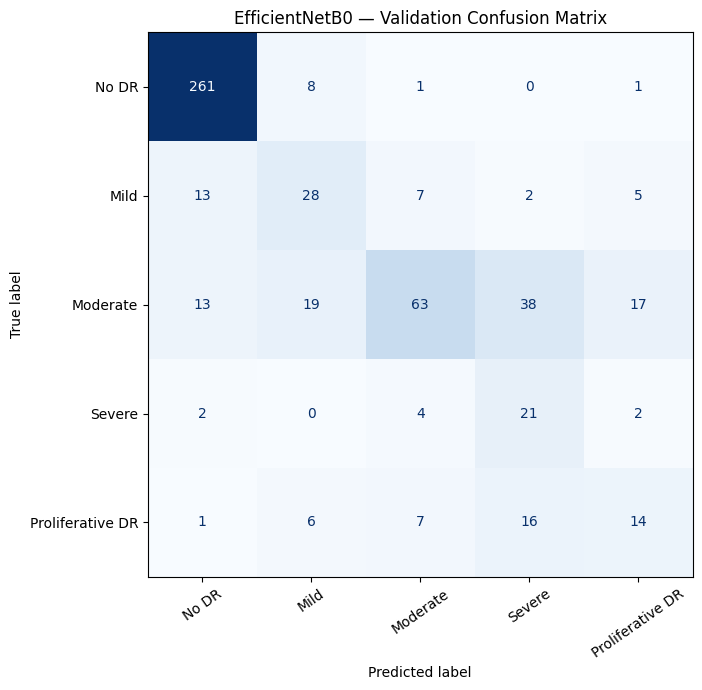


✅ Validation evaluation complete!
Test dataset has NOT been used.


In [8]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

MODEL_PATH = "/content/drive/MyDrive/aptos_efficientnet_best.keras"

# Load the actual saved best checkpoint
best_model = tf.keras.models.load_model(MODEL_PATH)

# Validation predictions only
val_probabilities = best_model.predict(val_ds, verbose=1)
val_predictions = np.argmax(val_probabilities, axis=1)

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

print("\n========== VALIDATION RESULTS ==========")

accuracy = accuracy_score(val_labels, val_predictions)
print(f"Validation Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        val_labels,
        val_predictions,
        labels=[0, 1, 2, 3, 4],
        target_names=class_names,
        digits=3,
        zero_division=0
    )
)

cm = confusion_matrix(
    val_labels,
    val_predictions,
    labels=[0, 1, 2, 3, 4]
)

fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=35,
    colorbar=False
)

plt.title("EfficientNetB0 — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

print("\n✅ Validation evaluation complete!")
print("Test dataset has NOT been used.")


In [9]:

import os
import numpy as np
import tensorflow as tf
from tensorflow import keras

OLD_MODEL_PATH = "/content/drive/MyDrive/aptos_efficientnet_best.keras"
NEW_MODEL_PATH = "/content/drive/MyDrive/aptos_efficientnet_finetuned.keras"

fine_model = keras.models.load_model(OLD_MODEL_PATH)

# Find EfficientNetB0 inside our model
base_model = next(
    layer for layer in fine_model.layers
    if isinstance(layer, keras.Model)
    and "efficientnet" in layer.name.lower()
)

# Allow fine-tuning of selected layers
base_model.trainable = True

for layer in base_model.layers[:-20]:
    layer.trainable = False

# Keep BatchNormalization frozen for stable transfer learning
for layer in base_model.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

fine_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

trainable_params = sum(
    np.prod(v.shape) for v in fine_model.trainable_weights
)

print("========== FINE-TUNING ==========")
print("Trainable parameters:", trainable_params)
print("New checkpoint:", NEW_MODEL_PATH)

fine_callbacks = [
    keras.callbacks.ModelCheckpoint(
        NEW_MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    )
]

fine_history = fine_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    class_weight=class_weights,
    callbacks=fine_callbacks,
    verbose=1
)

print("\n✅ FINE-TUNING FINISHED!")
print("Best fine-tuning validation accuracy:",
      round(max(fine_history.history["val_accuracy"]) * 100, 2), "%")
print("Best fine-tuning validation loss:",
      round(min(fine_history.history["val_loss"]), 4))


========== FINE-TUNING ==========
Trainable parameters: 1349173
New checkpoint: /content/drive/MyDrive/aptos_efficientnet_finetuned.keras
Epoch 1/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7217 - loss: 0.9309
Epoch 1: val_loss improved from None to 0.77029, saving model to /content/drive/MyDrive/aptos_efficientnet_finetuned.keras

Epoch 1: finished saving model to /content/drive/MyDrive/aptos_efficientnet_finetuned.keras
161/161 ━━━━━━━━━━━━━━━━━━━━ 304s 2s/step - accuracy: 0.7163 - loss: 0.9404 - val_accuracy: 0.6940 - val_loss: 0.7703
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7184 - loss: 0.9158
Epoch 2: val_loss improved from 0.77029 to 0.74893, saving model to /content/drive/MyDrive/aptos_efficientnet_finetuned.keras

Epoch 2: finished saving model to /content/drive/MyDrive/aptos_efficientnet_finetuned.keras
161/161 ━━━━━━━━━━━━━━━━━━━━ 271s 2s/step - accuracy: 0.7140 - loss: 0.9135 - val_accuracy: 0.7177 - val_loss: 0.7489
Epoch 3/5
161/161 ━━━━━

35/35 ━━━━━━━━━━━━━━━━━━━━ 47s 1s/step

========== FINE-TUNED VALIDATION RESULTS ==========
Accuracy: 72.68%
Macro F1: 0.5874

Classification Report:
                  precision    recall  f1-score   support

           No DR      0.913     0.963     0.937       271
            Mild      0.471     0.582     0.520        55
        Moderate      0.792     0.407     0.537       150
          Severe      0.365     0.655     0.469        29
Proliferative DR      0.394     0.591     0.473        44

        accuracy                          0.727       549
       macro avg      0.587     0.640     0.587       549
    weighted avg      0.765     0.727     0.724       549



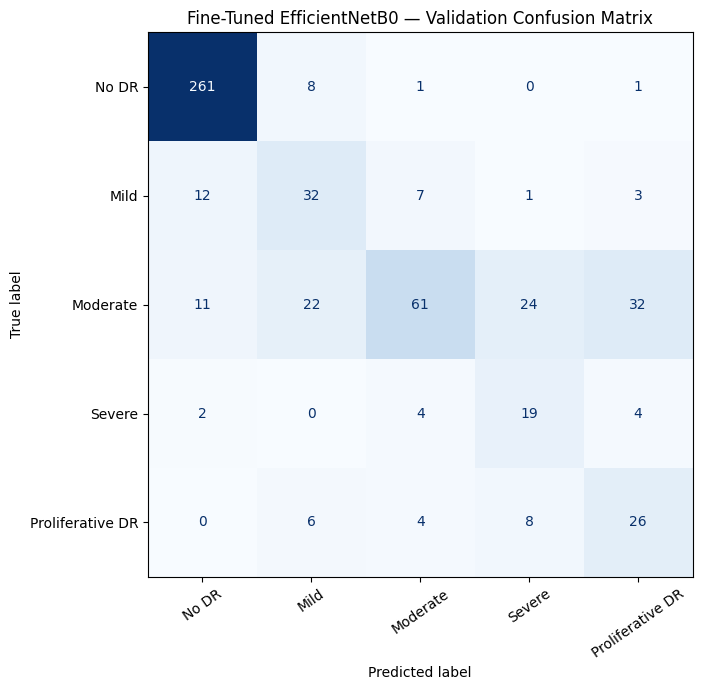


✅ Fine-tuned validation evaluation complete!
Test set remains untouched.


In [10]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

MODEL_PATH = "/content/drive/MyDrive/aptos_efficientnet_finetuned.keras"

fine_best = tf.keras.models.load_model(MODEL_PATH)

# Predict on validation data only
val_probs = fine_best.predict(val_ds, verbose=1)
val_preds = np.argmax(val_probs, axis=1)

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

print("\n========== FINE-TUNED VALIDATION RESULTS ==========")

print(
    "Accuracy:",
    f"{accuracy_score(val_labels, val_preds) * 100:.2f}%"
)

print(
    "Macro F1:",
    f"{f1_score(val_labels, val_preds, average='macro'):.4f}"
)

print("\nClassification Report:")
print(
    classification_report(
        val_labels,
        val_preds,
        labels=[0, 1, 2, 3, 4],
        target_names=class_names,
        digits=3,
        zero_division=0
    )
)

cm = confusion_matrix(
    val_labels,
    val_preds,
    labels=[0, 1, 2, 3, 4]
)

fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=35,
    colorbar=False
)

plt.title("Fine-Tuned EfficientNetB0 — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

print("\n✅ Fine-tuned validation evaluation complete!")
print("Test set remains untouched.")


========== FINAL TEST EVALUATION ==========
35/35 ━━━━━━━━━━━━━━━━━━━━ 51s 1s/step

Test Accuracy: 69.09%
Test Macro F1: 0.5155

Classification Report:
                  precision    recall  f1-score   support

           No DR      0.953     0.974     0.964       271
            Mild      0.500     0.554     0.525        56
        Moderate      0.754     0.327     0.456       150
          Severe      0.204     0.379     0.265        29
Proliferative DR      0.272     0.568     0.368        44

        accuracy                          0.691       550
       macro avg      0.536     0.560     0.515       550
    weighted avg      0.759     0.691     0.696       550



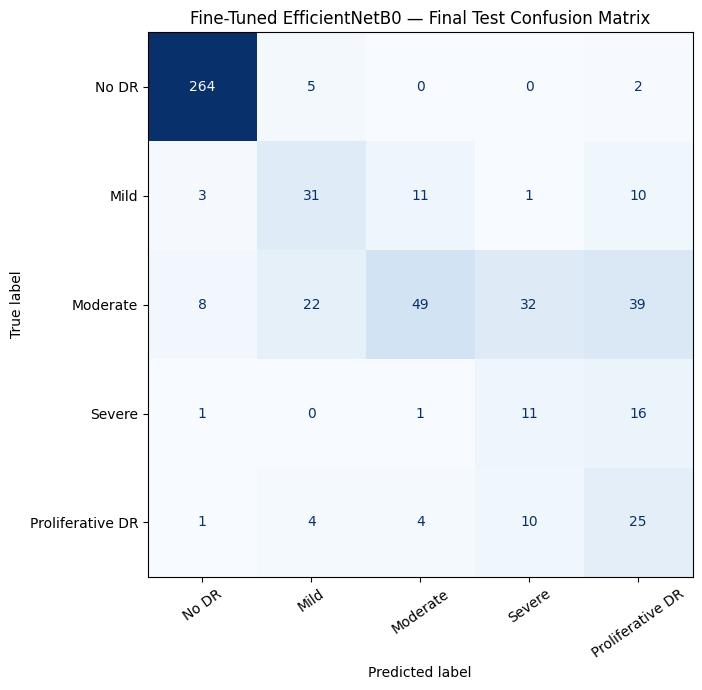


✅ FINAL TEST EVALUATION COMPLETE!


In [11]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

MODEL_PATH = "/content/drive/MyDrive/aptos_efficientnet_finetuned.keras"

final_model = tf.keras.models.load_model(MODEL_PATH)

print("========== FINAL TEST EVALUATION ==========")

# Test predictions — no augmentation during inference
test_probabilities = final_model.predict(test_ds, verbose=1)
test_predictions = np.argmax(test_probabilities, axis=1)

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

test_accuracy = accuracy_score(test_labels, test_predictions)
test_macro_f1 = f1_score(
    test_labels,
    test_predictions,
    average="macro"
)

print(f"\nTest Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Macro F1: {test_macro_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        test_labels,
        test_predictions,
        labels=[0, 1, 2, 3, 4],
        target_names=class_names,
        digits=3,
        zero_division=0
    )
)

cm = confusion_matrix(
    test_labels,
    test_predictions,
    labels=[0, 1, 2, 3, 4]
)

fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=35,
    colorbar=False
)

plt.title("Fine-Tuned EfficientNetB0 — Final Test Confusion Matrix")
plt.tight_layout()
plt.show()

print("\n✅ FINAL TEST EVALUATION COMPLETE!")


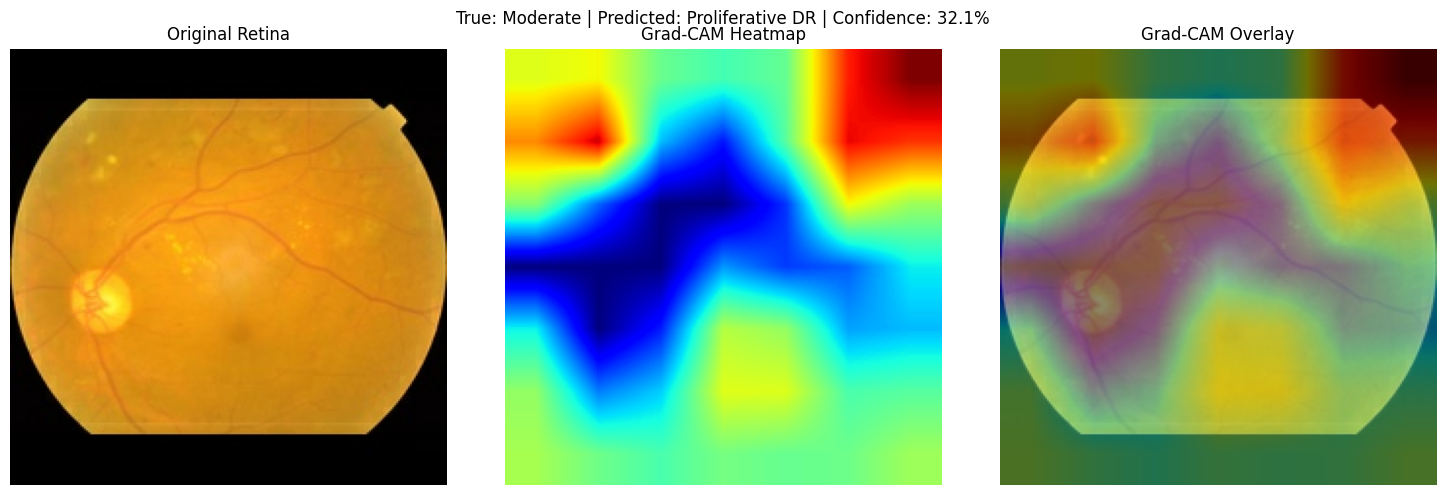

✅ Grad-CAM visualization generated!


In [12]:

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow import keras

MODEL_PATH = "/content/drive/MyDrive/aptos_efficientnet_finetuned.keras"

gradcam_model = keras.models.load_model(MODEL_PATH)

# Locate EfficientNet backbone
backbone = next(
    layer for layer in gradcam_model.layers
    if isinstance(layer, keras.Model)
    and "efficientnet" in layer.name.lower()
)

# Use the backbone's final convolutional feature map
last_conv_layer = backbone.get_layer("top_conv")

# Build a feature extractor from the backbone
feature_extractor = keras.Model(
    inputs=backbone.input,
    outputs=last_conv_layer.output
)

# Take one test image
sample_image, sample_label = next(iter(test_ds))
sample_image = sample_image[:1]
true_label = int(sample_label[0].numpy())

# Apply the same frozen inference path used by our classifier
with tf.GradientTape() as tape:
    features = feature_extractor(sample_image, training=False)
    tape.watch(features)

    # Reproduce EfficientNet's remaining top layers and classifier head
    x = backbone.get_layer("top_bn")(features, training=False)
    x = backbone.get_layer("top_activation")(x)
    x = gradcam_model.get_layer("global_average_pooling2d")(x)
    x = gradcam_model.get_layer("dropout")(x, training=False)
    predictions = gradcam_model.layers[-1](x)

    predicted_class = tf.argmax(predictions[0])
    score = predictions[:, predicted_class]

gradients = tape.gradient(score, features)

pooled_gradients = tf.reduce_mean(
    gradients,
    axis=(0, 1, 2)
)

heatmap = tf.reduce_sum(
    features[0] * pooled_gradients,
    axis=-1
)

heatmap = tf.maximum(heatmap, 0)
heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

heatmap = tf.image.resize(
    heatmap[..., tf.newaxis],
    (224, 224)
).numpy().squeeze()

image = sample_image[0].numpy().astype("uint8")

class_names = [
    "No DR", "Mild", "Moderate",
    "Severe", "Proliferative DR"
]

predicted_label = int(predicted_class.numpy())
confidence = float(tf.reduce_max(predictions[0]).numpy())

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original Retina")

axes[1].imshow(heatmap, cmap="jet")
axes[1].set_title("Grad-CAM Heatmap")

axes[2].imshow(image)
axes[2].imshow(heatmap, cmap="jet", alpha=0.45)
axes[2].set_title("Grad-CAM Overlay")

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"True: {class_names[true_label]} | "
    f"Predicted: {class_names[predicted_label]} | "
    f"Confidence: {confidence:.1%}"
)

plt.tight_layout()
plt.show()

print("✅ Grad-CAM visualization generated!")


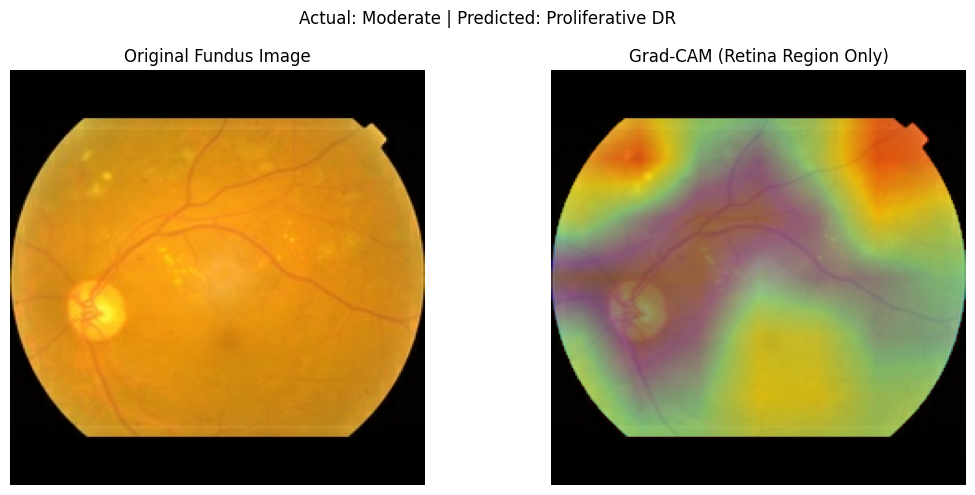


========== CLASS PROBABILITIES ==========
0. No DR: 0.05%
1. Mild: 13.34%
2. Moderate: 25.33%
3. Severe: 29.16%
4. Proliferative DR: 32.13%

Predicted class: Proliferative DR
Confidence: 32.13%

✅ Improved Grad-CAM visualization ready!


In [13]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Reuse variables from previous Grad-CAM cell:
# image, heatmap, predictions, true_label, predicted_label, class_names

# Identify retinal region using image brightness
brightness = image.astype(np.float32).mean(axis=2)
retina_mask = brightness > 15

# Hide Grad-CAM outside visible retinal region
masked_heatmap = np.ma.masked_where(
    ~retina_mask,
    heatmap
)

# Display original image and improved overlay
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].imshow(image)
axes[0].set_title("Original Fundus Image")
axes[0].axis("off")

axes[1].imshow(image)
axes[1].imshow(
    masked_heatmap,
    cmap="jet",
    alpha=0.40,
    vmin=0,
    vmax=1
)
axes[1].set_title("Grad-CAM (Retina Region Only)")
axes[1].axis("off")

plt.suptitle(
    f"Actual: {class_names[true_label]} | "
    f"Predicted: {class_names[predicted_label]}"
)
plt.tight_layout()
plt.show()

# Show probabilities for all five classes
probs = predictions[0].numpy()

print("\n========== CLASS PROBABILITIES ==========")

for i, (name, prob) in enumerate(zip(class_names, probs)):
    print(f"{i}. {name}: {prob * 100:.2f}%")

print("\nPredicted class:", class_names[predicted_label])
print("Confidence:", f"{probs[predicted_label] * 100:.2f}%")

print("\n✅ Improved Grad-CAM visualization ready!")


📤 Upload a retinal fundus image (JPG or PNG)


Saving 000c1434d8d7.png to 000c1434d8d7.png


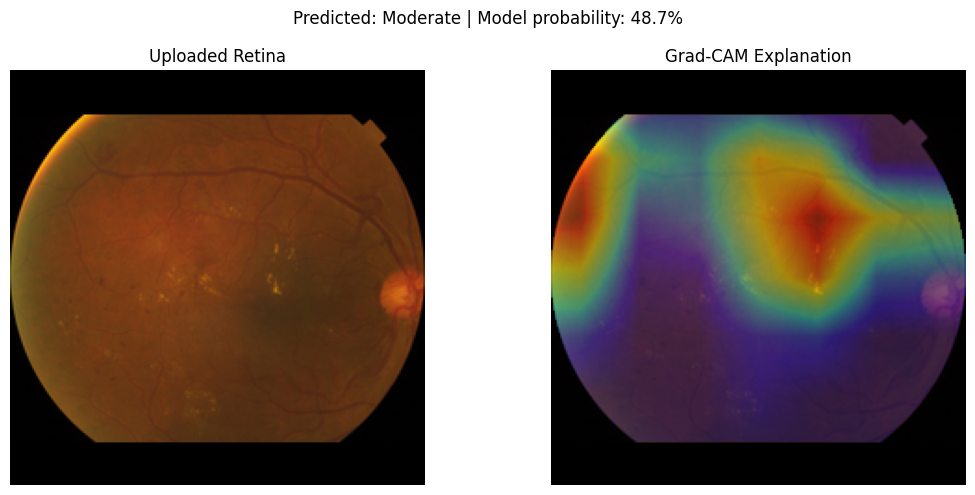


========== DR PREDICTION ==========
Uploaded file: 000c1434d8d7.png
Predicted severity: Moderate

Class probabilities:
No DR: 0.05%
Mild: 7.69%
Moderate: 48.68%
Severe: 17.51%
Proliferative DR: 26.07%

⚠️ Research prototype only — not for medical diagnosis.


In [14]:

import io
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image, ImageOps
from google.colab import files
from tensorflow import keras

# Load final model
demo_model = keras.models.load_model(
    "/content/drive/MyDrive/aptos_efficientnet_finetuned.keras"
)

class_names = [
    "No DR", "Mild", "Moderate",
    "Severe", "Proliferative DR"
]

# Upload image
print("📤 Upload a retinal fundus image (JPG or PNG)")
uploaded = files.upload()

if not uploaded:
    raise ValueError("No image uploaded.")

filename = next(iter(uploaded))
raw_bytes = uploaded[filename]

# Same preprocessing used for training
with Image.open(io.BytesIO(raw_bytes)) as img:
    img = img.convert("RGB")

    arr = np.asarray(img)
    brightness = arr.mean(axis=2)
    mask = brightness > 10

    if mask.any():
        ys, xs = np.where(mask)
        img = img.crop((
            int(xs.min()), int(ys.min()),
            int(xs.max()) + 1, int(ys.max()) + 1
        ))

    img = ImageOps.pad(
        img,
        (224, 224),
        method=Image.Resampling.LANCZOS,
        color=(0, 0, 0)
    )

    image = np.asarray(img, dtype=np.uint8)

input_tensor = tf.convert_to_tensor(
    image[np.newaxis, ...],
    dtype=tf.float32
)

# Normal model prediction
probs = demo_model(input_tensor, training=False).numpy()[0]
pred_idx = int(np.argmax(probs))

# EfficientNet backbone and final convolution layer
backbone = next(
    layer for layer in demo_model.layers
    if isinstance(layer, keras.Model)
    and "efficientnet" in layer.name.lower()
)

feature_extractor = keras.Model(
    backbone.input,
    backbone.get_layer("top_conv").output
)

# Grad-CAM for predicted class
with tf.GradientTape() as tape:
    features = feature_extractor(input_tensor, training=False)
    tape.watch(features)

    x = backbone.get_layer("top_bn")(features, training=False)
    x = backbone.get_layer("top_activation")(x)
    x = demo_model.get_layer("global_average_pooling2d")(x)
    x = demo_model.get_layer("dropout")(x, training=False)
    grad_predictions = demo_model.layers[-1](x)

    target_score = grad_predictions[:, pred_idx]

grads = tape.gradient(target_score, features)
weights = tf.reduce_mean(grads, axis=(0, 1, 2))

heatmap = tf.reduce_sum(features[0] * weights, axis=-1)
heatmap = tf.maximum(heatmap, 0)
heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

heatmap = tf.image.resize(
    heatmap[..., tf.newaxis],
    (224, 224)
).numpy().squeeze()

# Hide heatmap on black background
retina_mask = image.mean(axis=2) > 15
masked_heatmap = np.ma.masked_where(~retina_mask, heatmap)

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].imshow(image)
axes[0].set_title("Uploaded Retina")
axes[0].axis("off")

axes[1].imshow(image)
axes[1].imshow(
    masked_heatmap,
    cmap="jet",
    alpha=0.40,
    vmin=0,
    vmax=1
)
axes[1].set_title("Grad-CAM Explanation")
axes[1].axis("off")

plt.suptitle(
    f"Predicted: {class_names[pred_idx]} | "
    f"Model probability: {probs[pred_idx]:.1%}"
)
plt.tight_layout()
plt.show()

print("\n========== DR PREDICTION ==========")
print("Uploaded file:", filename)
print("Predicted severity:", class_names[pred_idx])

print("\nClass probabilities:")
for name, prob in zip(class_names, probs):
    print(f"{name}: {prob * 100:.2f}%")

print("\n⚠️ Research prototype only — not for medical diagnosis.")


In [15]:

import os
import json
import zipfile
from google.colab import files

OUTPUT_ZIP = "/content/DR_Hackathon_Project_Backup.zip"
DATA_DIR = "/content/aptos_full"
DRIVE_DIR = "/content/drive/MyDrive"

backup_files = {
    "models/efficientnet_original.keras":
        os.path.join(DRIVE_DIR, "aptos_efficientnet_best.keras"),
    "models/efficientnet_finetuned.keras":
        os.path.join(DRIVE_DIR, "aptos_efficientnet_finetuned.keras"),
    "data/train.csv":
        os.path.join(DATA_DIR, "train.csv"),
    "data/train_split.csv":
        os.path.join(DATA_DIR, "train_split.csv"),
    "data/val_split.csv":
        os.path.join(DATA_DIR, "val_split.csv"),
    "data/test_split.csv":
        os.path.join(DATA_DIR, "test_split.csv")
}

readme = """# Explainable AI for Diabetic Retinopathy Screening

Hackathon research prototype.

Dataset: APTOS 2019 Blindness Detection
Architecture: EfficientNetB0
Classes: No DR, Mild, Moderate, Severe, Proliferative DR

Final fine-tuned model:
Test accuracy: 69.09%
Test macro F1: 0.5155

This model is NOT validated for clinical diagnosis.

Important:
- Original dataset images are NOT included in this ZIP.
- The original dataset ZIP is stored separately in Google Drive.
- Model training and Grad-CAM code currently lives in the Colab notebook.
"""

with zipfile.ZipFile(
    OUTPUT_ZIP,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=1,
    allowZip64=True
) as z:
    z.writestr("README.md", readme)

    for archive_name, source_path in backup_files.items():
        if os.path.isfile(source_path):
            z.write(source_path, arcname=archive_name)
            print("✅ Added:", archive_name)
        else:
            print("⚠️ Missing:", source_path)

    # Include notebook files if present locally
    for filename in os.listdir("/content"):
        if filename.endswith(".ipynb"):
            z.write(
                os.path.join("/content", filename),
                arcname=f"notebooks/{filename}"
            )
            print("✅ Added notebook:", filename)

print("\n========== BACKUP READY ==========")
print("ZIP:", OUTPUT_ZIP)
print("Size (MB):", round(os.path.getsize(OUTPUT_ZIP) / 1024**2, 2))

print("\nStarting download...")
files.download(OUTPUT_ZIP)


✅ Added: models/efficientnet_original.keras
✅ Added: models/efficientnet_finetuned.keras
✅ Added: data/train.csv
✅ Added: data/train_split.csv
✅ Added: data/val_split.csv
✅ Added: data/test_split.csv

========== BACKUP READY ==========
ZIP: /content/DR_Hackathon_Project_Backup.zip
Size (MB): 38.58

Starting download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:

import sys
import subprocess

# Install OpenAI Python SDK
subprocess.check_call([
    sys.executable, "-m", "pip",
    "install", "-q", "openai"
])

from google.colab import userdata
from openai import OpenAI

# Securely retrieve API key from Colab Secrets
groq_api_key = userdata.get("GROQ_API_KEY")

if not groq_api_key:
    raise ValueError(
        "GROQ_API_KEY missing. Add it in Colab Secrets "
        "and enable notebook access."
    )

# OpenAI-compatible SDK connected to Groq
groq_client = OpenAI(
    api_key=groq_api_key,
    base_url="https://api.groq.com/openai/v1"
)

GROQ_MODEL = "openai/gpt-oss-120B"

# Verify connection with a minimal API request
response = groq_client.chat.completions.create(
    model=GROQ_MODEL,
    messages=[
        {
            "role": "user",
            "content": "Reply with exactly: Groq connection successful"
        }
    ],
    temperature=0,
    max_tokens=30
)

print("SDK: OpenAI Python SDK")
print("Provider: Groq")
print("Model:", GROQ_MODEL)
print("Response:", response.choices[0].message.content)
print("✅ GenAI connection ready!")


SDK: OpenAI Python SDK
Provider: Groq
Model: openai/gpt-oss-120B
Response: 
✅ GenAI connection ready!


In [19]:

import numpy as np

# Use prediction probabilities from our previous demo
probabilities = {
    name: round(float(prob) * 100, 2)
    for name, prob in zip(class_names, probs)
}

predicted_severity = class_names[int(np.argmax(probs))]
top_probability = float(np.max(probs)) * 100

system_prompt = """
You are a medical AI communication assistant for a research
prototype on diabetic retinopathy screening in rural India.

You are NOT a doctor and must NOT diagnose disease.

Your job is to explain the supplied machine-learning model
output in simple, understandable Hinglish.

Rules:
1. Use only the provided prediction and probabilities.
2. Never claim to have examined the retinal image.
3. Never invent lesions, bleeding, exudates or other findings.
4. Explain that probabilities are uncalibrated model scores,
   not confirmed medical confidence.
5. Clearly state that this model is experimental and has
   limited accuracy, especially for serious DR classes.
6. Recommend review by a qualified eye specialist.
7. Do not prescribe medication or treatment.
8. Keep the explanation concise and easy to understand.

Structure:
- Predicted DR severity
- Simple Hinglish explanation
- Model uncertainty
- Suggested next step
- Important disclaimer
"""

user_prompt = f"""
Generate a Hinglish screening explanation report.

Predicted severity: {predicted_severity}
Highest model probability: {top_probability:.2f}%

All model probabilities:
{probabilities}

Model evaluation:
Test accuracy: 69.09%
Test macro F1: 0.5155
Severe DR test recall: 37.9%

This is an experimental hackathon prototype.
"""

response = groq_client.chat.completions.create(
    model=GROQ_MODEL,
    messages=[
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_prompt}
    ],
    temperature=0.2,
    max_tokens=650
)

genai_report = response.choices[0].message.content

print("========== AI-GENERATED DR REPORT ==========\n")
print(genai_report)
print("\n✅ Groq GenAI report generated!")


========== AI-GENERATED DR REPORT ==========

**Predicted DR severity:** Moderate  

**Simple Hinglish explanation:**  
Model ne aapke retinal image ko dekhkar “Moderate diabetic retinopathy” sabse zyada probability (48.68 %) ke saath predict kiya hai. Iska matlab hai ki kuch changes ho sakte hain jo moderate level ki DR se jude hote hain, lekin hum isko sirf ek computer ki guess ke roop mein dekh rahe hain.  

**Model uncertainty:**  
- No DR: 5 %  
- Mild: 7.69 %  
- Moderate: **48.68 %** (sabse high)  
- Severe: 17.51 %  
- Proliferative DR: 26.07 %  

Ye percentages model ke raw scores hain, calibrated confidence nahi hain. Model ki overall test accuracy 69 % hai aur serious classes (Severe, Proliferative) ki recall bahut kam (≈38 % for Severe), isliye predictions kaafi uncertain ho sakte hain.  

**Suggested next step:**  
Is result ko turant ek qualified eye specialist (ophthalmologist) ko dikhayein. Unka clinical examination aur, agar zaroori ho, fundus photography ya OCT jaise 